# FLARE FireOutlook: explore seven forecast days

One issuance, seven consecutive daily forecasts. This native-grid sample around
Wheeler County, Oregon, was issued **November 2, 2026 at 03:00 UTC**. It is a
regional example of FireOutlook2.0, separate from the July v11 Day-1 case study.

Day 1 uses HRRR; Day 2 combines HRRR and NBM; Days 3-7 use NBM and remain
experimental. Vegetation, snow support, and the prior are frozen at issuance.
The index represents relative fire danger, rather than a probability.

Install `outlook/requirements.txt` and run this notebook from the cloned
repository. The sample and its checksum manifest are included.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = next((base for parent in [cwd, *cwd.parents]
             for base in (parent / "outlook", parent)
             if (base / "examples" / "seven_day.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from within the cloned repository")
sys.path.insert(0, str(ROOT / "examples"))
from seven_day import open_sample, schedule, select_day, plot_week, point_forecast, flag_names, LABELS
ds = open_sample()
print("Checksum verified")
print("Issued:", ds.attrs["issue_time"])
print("Algorithm:", ds.attrs["algorithm_version"])
print("Sample dimensions:", dict(ds.sizes))

Checksum verified
Issued: 2026-11-02T03:00Z
Algorithm: FireOutlook2.0-hrrr1-hybrid2-nbm3to7-2
Sample dimensions: {'forecast_day': 7, 'y': 193, 'x': 348}


## 1. Read the forecast windows

Each row is a lead from the same issuance. Valid windows are in UTC and run from
12:00 to 12:00 the next day. The completion marker must be true before use.
The weather cycle is an initialization time, not the time of the fire-danger forecast.

In [2]:
display(schedule(ds))
assert ds.complete.values.all()
print(ds.attrs["forecast_policy"])

,forecast_day,valid_start_UTC,valid_end_UTC,weather_cycle_UTC,weather_model,complete
0,1,2026-11-02 12:00:00+00:00,2026-11-03 12:00:00+00:00,2026-11-02 00:00:00+00:00,HRRR,True
1,2,2026-11-03 12:00:00+00:00,2026-11-04 12:00:00+00:00,2026-11-02 00:00:00+00:00,HYBRID,True
2,3,2026-11-04 12:00:00+00:00,2026-11-05 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True
3,4,2026-11-05 12:00:00+00:00,2026-11-06 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True
4,5,2026-11-06 12:00:00+00:00,2026-11-07 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True
5,6,2026-11-07 12:00:00+00:00,2026-11-08 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True
6,7,2026-11-08 12:00:00+00:00,2026-11-09 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True


HRRR Day 1; Day 2 uses HRRR f36-f47 plus NBM f48-f60; NBM Days 3-7 experimental; vegetation, snow and prior frozen at issue


## 2. Read categories from the product

The maps use the stored categories. Code 0 means unavailable; codes 1-6 describe
increasing danger. These version-specific boundaries come from the file, rather
than the rounded boundaries in older story displays.

In [3]:
bounds = [0.0, *np.asarray(ds.attrs["category_edges"]).tolist(), 1.0]
display(pd.DataFrame({
    "code": range(1, 7), "category": LABELS[1:],
    "lower_inclusive": bounds[:-1], "upper": bounds[1:],
    "upper_inclusive": [False] * 5 + [True],
}))

,code,category,lower_inclusive,upper,upper_inclusive
0,1,Minimal,0.000000,0.442030,False
1,2,Low,0.442030,0.612400,False
2,3,Moderate,0.612400,0.707382,False
3,4,High,0.707382,0.758083,False
4,5,Very high,0.758083,0.810251,False
5,6,Extreme,0.810251,1.000000,True


## 3. Compare the seven daily maps

All panels share a category legend and the original two-dimensional geographic
coordinates. The rectangular sample includes land around Wheeler County; it is
not clipped to the county boundary. Gray marks unavailable pixels.

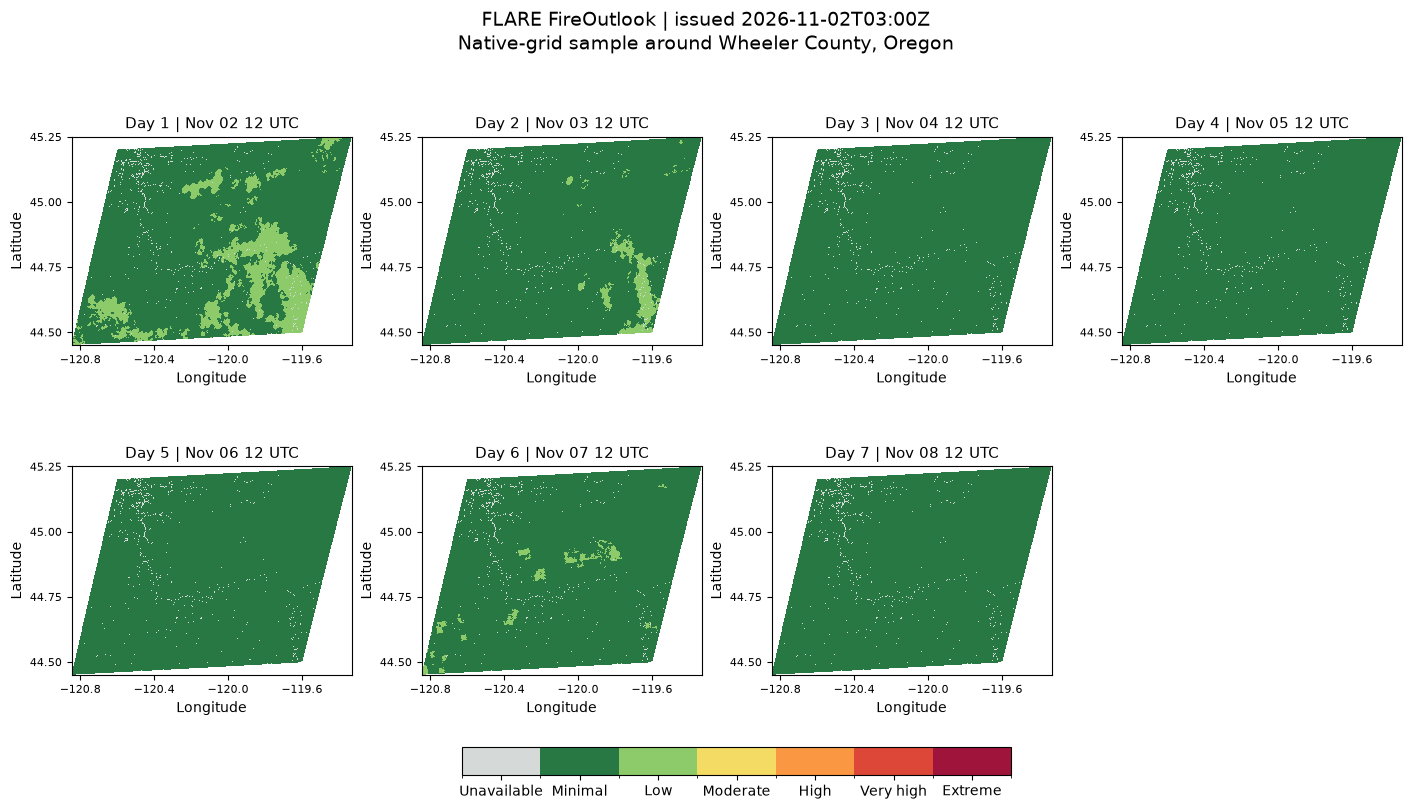

In [4]:
fig = plot_week(ds)
plt.show()

## 4. Inspect a location

Change the latitude and longitude within the sample. All seven values use the
same nearest native-grid pixel. The chosen coordinate is an example location,
not an assertion that a fire occurred during this forecast period.

,forecast_day,valid_start_UTC,valid_end_UTC,weather_cycle_UTC,weather_model,complete,index,category,quality_flags,latitude,longitude,distance_km,quality_notes
0,1,2026-11-02 12:00:00+00:00,2026-11-03 12:00:00+00:00,2026-11-02 00:00:00+00:00,HRRR,True,0.378554,Minimal,0,44.757076,-120.063339,0.003776,None set
1,2,2026-11-03 12:00:00+00:00,2026-11-04 12:00:00+00:00,2026-11-02 00:00:00+00:00,HYBRID,True,0.330879,Minimal,64,44.757076,-120.063339,0.003776,experimental longer lead
2,3,2026-11-04 12:00:00+00:00,2026-11-05 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True,0.050047,Minimal,64,44.757076,-120.063339,0.003776,experimental longer lead
3,4,2026-11-05 12:00:00+00:00,2026-11-06 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True,0.165986,Minimal,64,44.757076,-120.063339,0.003776,experimental longer lead
4,5,2026-11-06 12:00:00+00:00,2026-11-07 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True,0.234740,Minimal,64,44.757076,-120.063339,0.003776,experimental longer lead
5,6,2026-11-07 12:00:00+00:00,2026-11-08 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True,0.343103,Minimal,64,44.757076,-120.063339,0.003776,experimental longer lead
6,7,2026-11-08 12:00:00+00:00,2026-11-09 12:00:00+00:00,2026-11-02 00:00:00+00:00,NBM,True,0.206348,Minimal,64,44.757076,-120.063339,0.003776,experimental longer lead


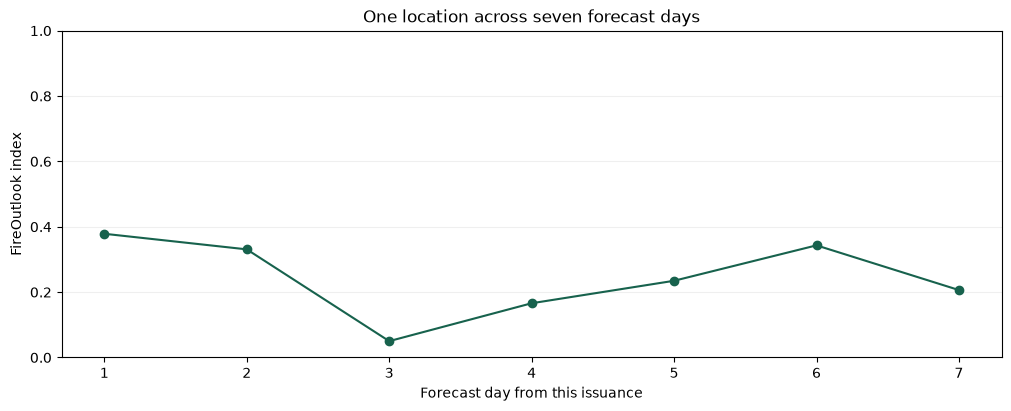

In [5]:
latitude, longitude = 44.7571, -120.0633
point = point_forecast(ds, latitude, longitude)
point["quality_notes"] = [", ".join(flag_names(ds, int(v))) or "None set"
                          for v in point.quality_flags]
display(point)
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(point.forecast_day, point["index"], marker="o", color="#17624d")
ax.set(xticks=range(1, 8), ylim=(0, 1), xlabel="Forecast day from this issuance",
       ylabel="FireOutlook index", title="One location across seven forecast days")
ax.grid(axis="y", alpha=.2)
plt.show()

## 5. Export and explore

The CSV retains lead numbers, valid periods, weather models, selected coordinates,
categories, and quality flags. This walkthrough checks data integrity and time
alignment; predictive skill requires a separate evaluation against observations.

In [6]:
output = ROOT / "outputs"
output.mkdir(exist_ok=True)
point.to_csv(output / "seven_day_point_forecast.csv", index=False)
print("Saved outputs/seven_day_point_forecast.csv")
ds.close()

Saved outputs/seven_day_point_forecast.csv
